
# Defense-in-Depth Safety Architectures for Clinical AI
### High-reliability engineering principles for autonomous clinical agents

**Prepared By Mehar Ali**

**MS Artificial Intelligence**

**Research prototype — synthetic clinical data only.**

This Colab demonstrates a layered safety architecture inspired by high-reliability engineering:

- Continuous patient-condition monitoring
- Data-quality monitoring
- Advisory predictive model
- Distribution-drift monitoring using PSI
- Predictive maintenance / degradation forecasting
- Uncertainty monitoring
- Deterministic safety state machine
- Generative-AI agent abstraction
- Deterministic safety arbiter
- Fail-safe escalation
- Auditability and traceability
- Computational architecture graph
- Fault-injection experiments
- Safety metrics

> **Safety notice:** This is an engineering/research prototype. It is not a medical device, clinical decision-support system, or substitute for clinical judgment. It uses synthetic data and deliberately simplified thresholds.



## Mathematical safety model

Let the monitored clinical state be

\[
x_t=[HR_t,SBP_t,SpO2_t,Temp_t,RR_t,Lactate_t,\ldots].
\]

A condition-monitoring score is

\[
C_t=w^Tz(x_t)
\]

where \(z(x_t)\) is a normalized vector of physiological/data-quality indicators.

Distribution shift is measured using Population Stability Index:

\[
PSI=\sum_i(p_i-q_i)\ln\left(\frac{p_i}{q_i}\right).
\]

A predictive-maintenance model forecasts future error:

\[
\hat E_{t+h}=f(PSI_t,\Delta PSI_t,R_t,\Delta R_t,A_t).
\]

The deterministic safety policy is:

\[
A_t =
\begin{cases}
FAIL\_SAFE,&C_t\ge\tau_C^{high}\\
FAIL\_SAFE,&PSI_t\ge\tau_D^{high}\\
RESTRICTED,&C_t\ge\tau_C\\
RESTRICTED,&PSI_t\ge\tau_D\land\hat E_{t+h}\ge\tau_E\\
DEGRADED,&U_t\ge\tau_U\\
NORMAL,&otherwise.
\end{cases}
\]

The crucial design property is:

**LLM output is a proposal, never the final authorization.**


1. Environment ready.
Synthetic records: 40000
Patients: 250
Condition alarms: 291


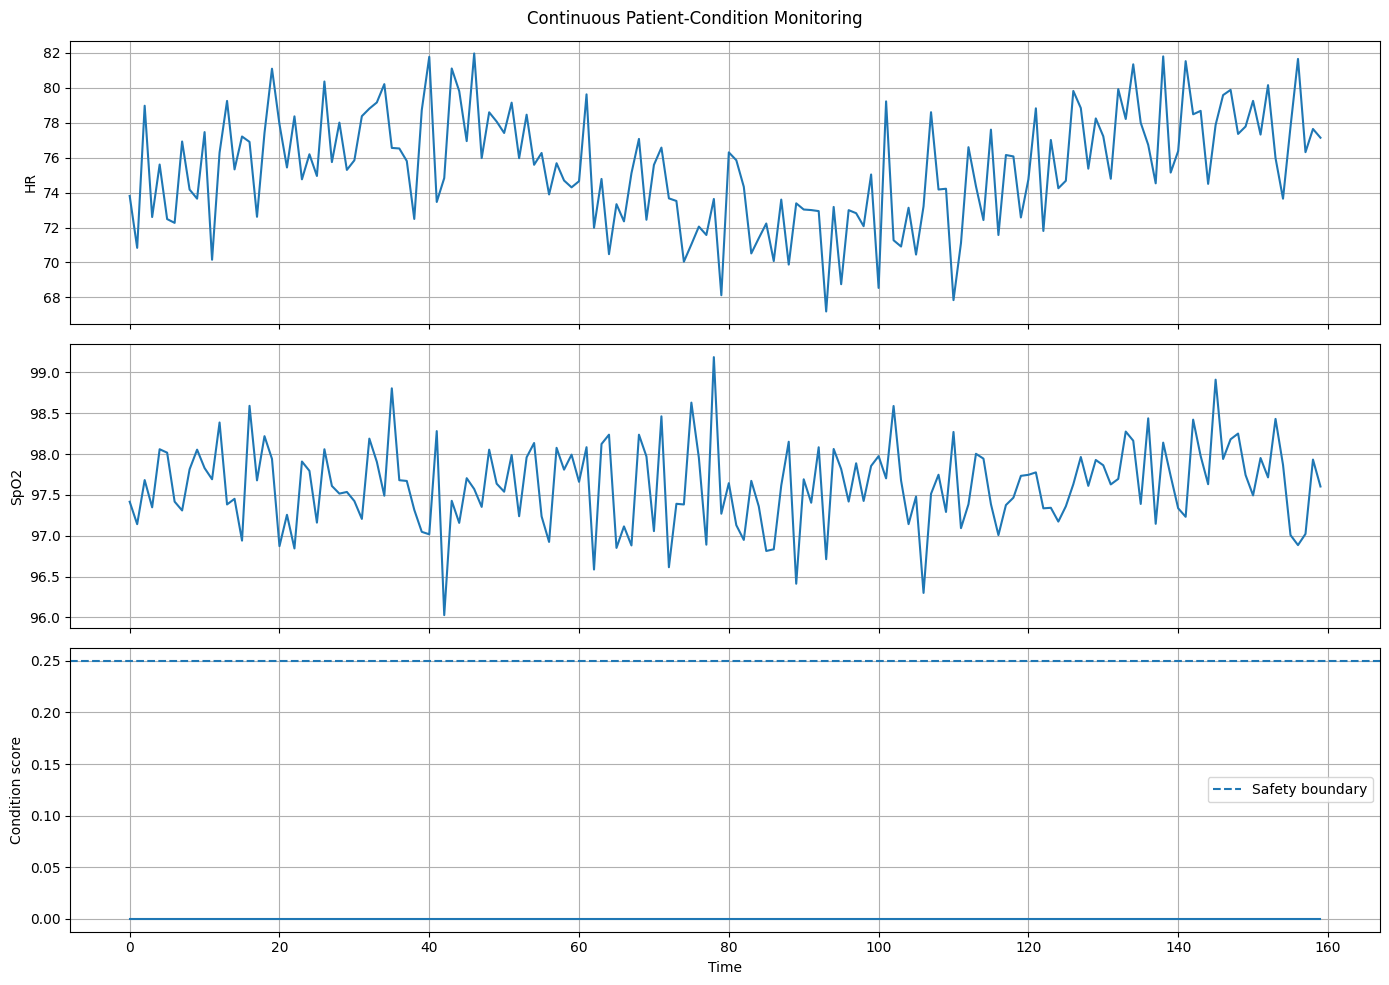

Advisory model AUROC: 0.9665
Advisory model Brier: 0.0475


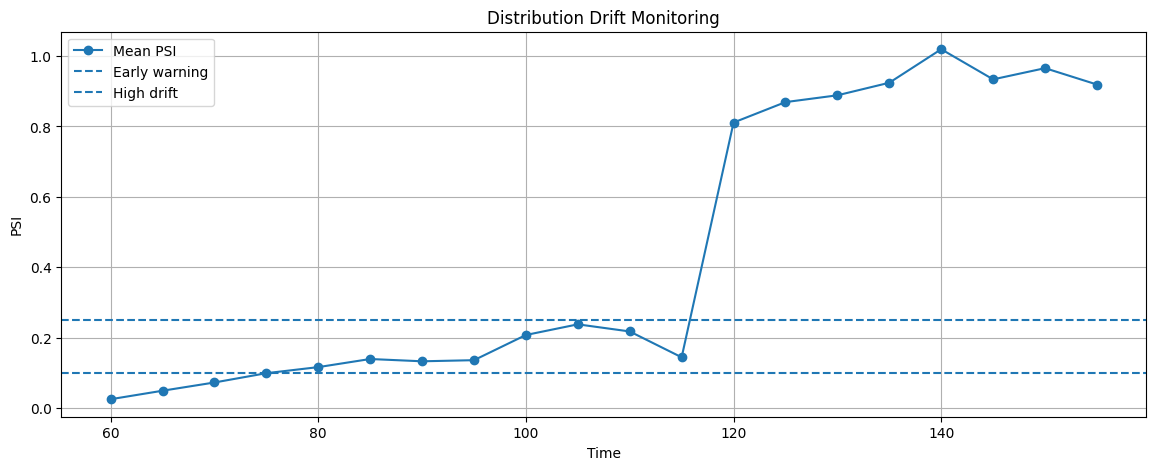

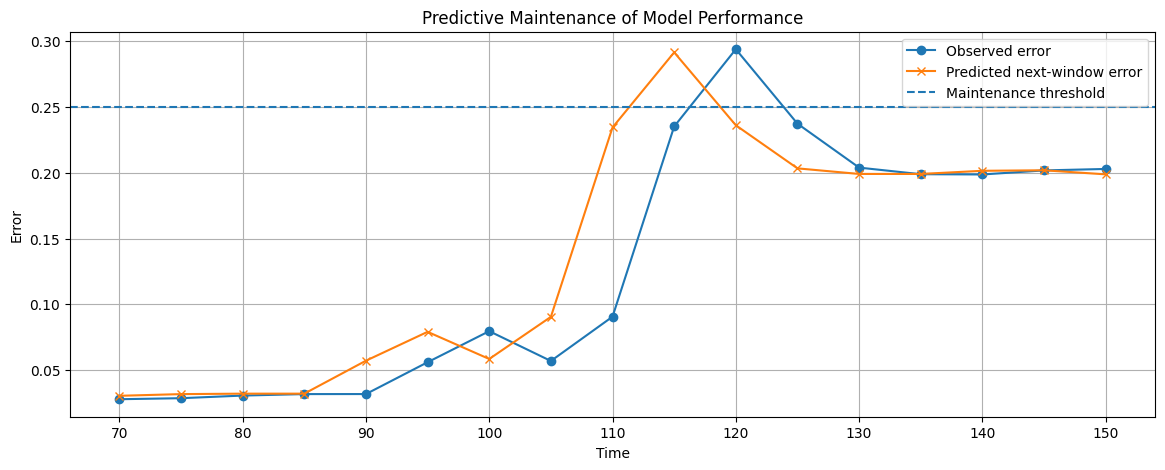

Safety-state distribution:
safety_state
FAIL_SAFE     3518
NORMAL        1021
RESTRICTED     417
DEGRADED        44
Name: count, dtype: int64

Safety metrics
-----------------------------
Advisory AUROC: 0.9647
Advisory Brier: 0.0498
False-negative rate: 0.9897
False-positive rate: 0.8185
Intervention rate: 0.787
Mean defense depth: 1.142


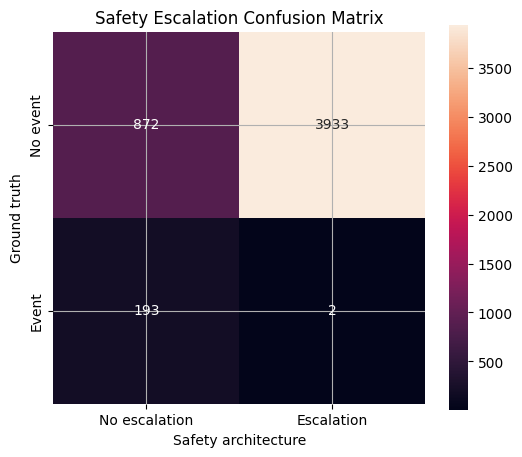

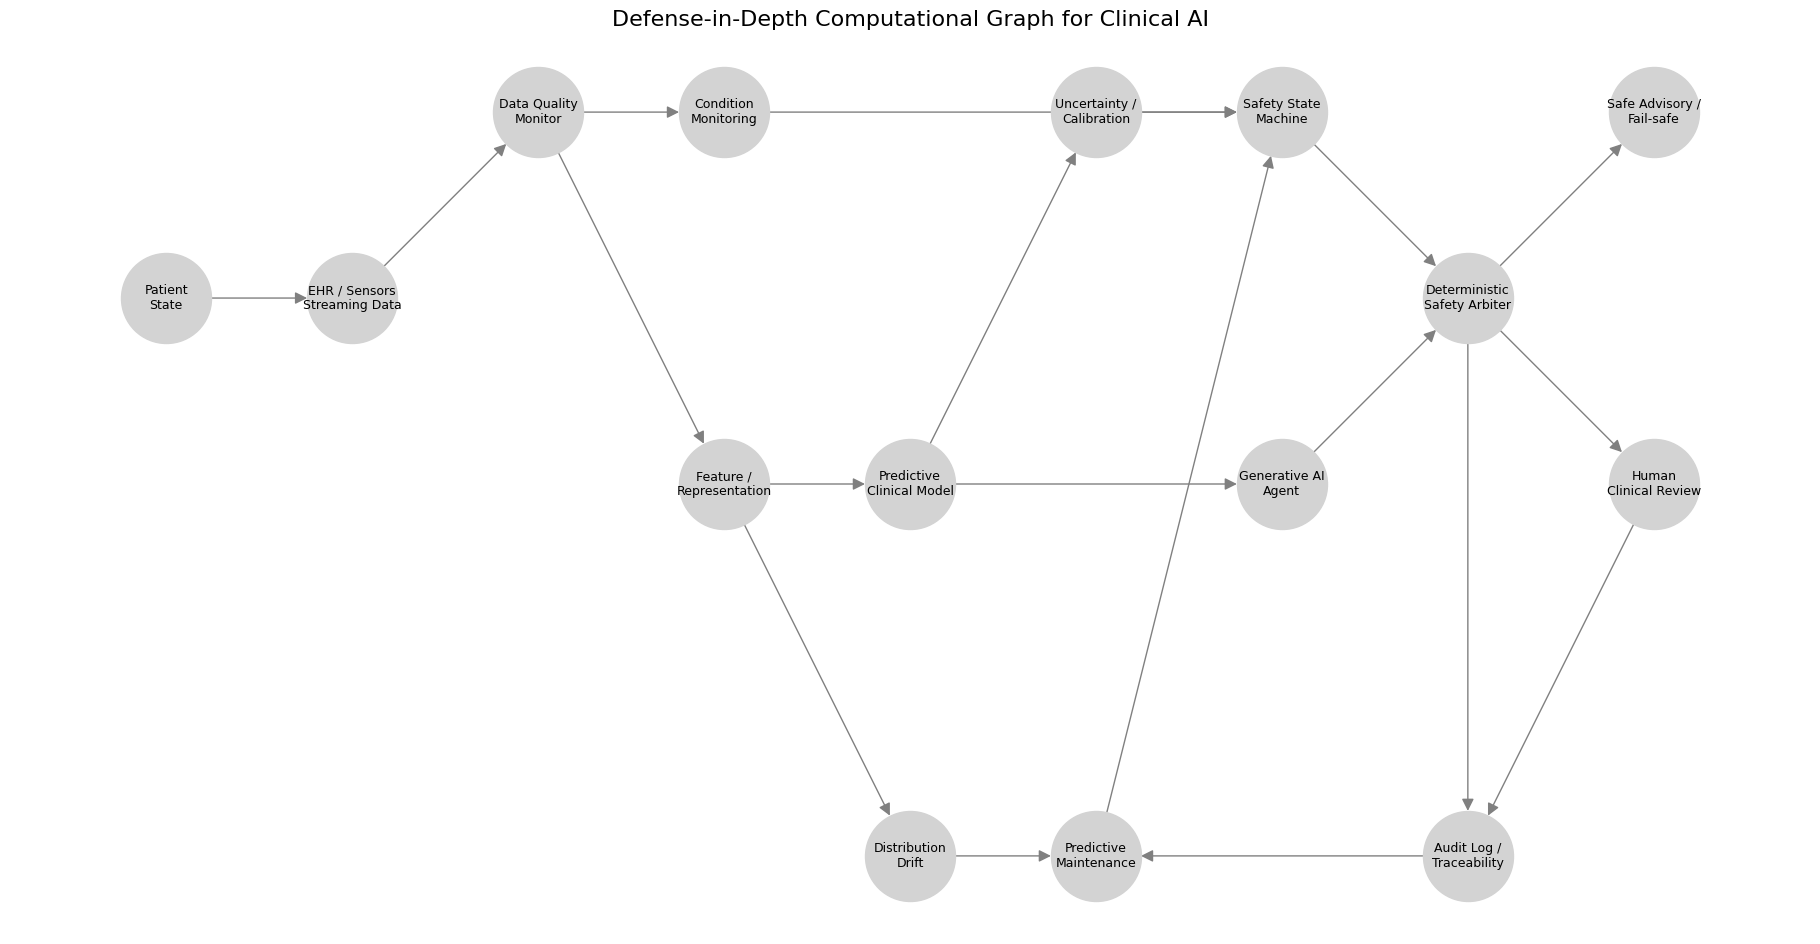

,test,safety_state,reason,decision,proposal,model_risk
0,Normal operation,NORMAL,No deterministic safety boundary crossed,ADVISORY_OUTPUT_ONLY,Lower predicted risk. Continue monitoring subj...,0.10
1,Physiological alarm,FAIL_SAFE,Severe monitored-condition violation,FAIL_SAFE_AND_ESCALATE,Lower predicted risk. Continue monitoring subj...,0.10
2,High distribution drift,FAIL_SAFE,High distribution drift,FAIL_SAFE_AND_ESCALATE,Lower predicted risk. Continue monitoring subj...,0.10
3,Predicted model degradation,RESTRICTED,Predicted model degradation,NO_AUTONOMOUS_ACTION,Lower predicted risk. Continue monitoring subj...,0.10
4,High uncertainty,DEGRADED,High model uncertainty,RESTRICTED_ADVISORY,Intermediate predicted risk. Recommend additio...,0.50
5,Compound failure,RESTRICTED,Condition-monitoring alarm,NO_AUTONOMOUS_ACTION,Lower predicted risk. Continue monitoring subj...,0.01


,mean,median,max,count
true_event,,,,
0.0,1.146514,1.0,3,4805
1.0,1.025641,1.0,2,195


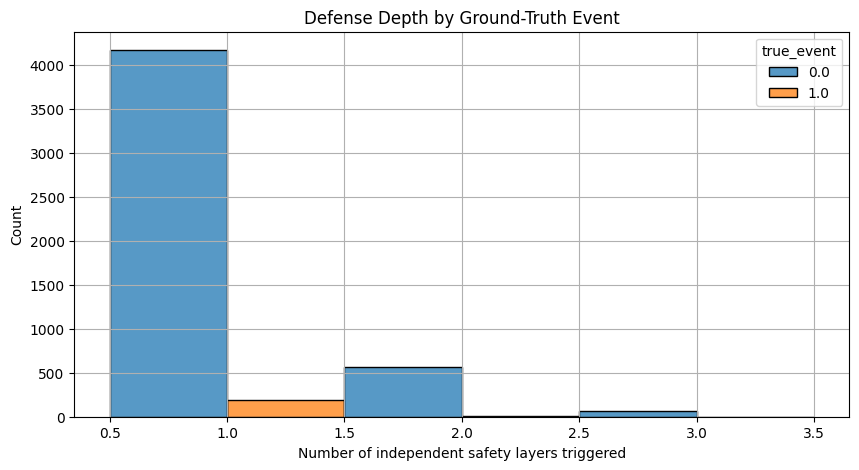

,0
patient_id,7
timestamp,120
model_version,risk-model-v1.0
policy_version,safety-policy-v1.0
condition_score,0.31
model_risk,0.76
uncertainty,0.12
psi,0.18
predicted_error,0.29
safety_state,RESTRICTED



DEFENSE-IN-DEPTH CLINICAL AI SAFETY ARCHITECTURE

LAYER 1  -> Data quality / provenance
LAYER 2  -> Continuous patient-condition monitoring
LAYER 3  -> Advisory predictive clinical model
LAYER 4  -> Uncertainty / calibration monitoring
LAYER 5  -> Distribution-drift detection
LAYER 6  -> Predictive maintenance of model health
LAYER 7  -> Deterministic safety state machine
LAYER 8  -> Generative AI agent
LAYER 9  -> Deterministic safety arbiter
LAYER 10 -> Human escalation / fail-safe
LAYER 11 -> Immutable audit and traceability

CORE PRINCIPLE:
    Generative AI proposes.
    Monitoring evaluates.
    Deterministic policy controls.
    Humans retain clinical authority.

This separation is the central defense-in-depth property.



In [1]:

# ============================================================
# END-TO-END PROJECT
# Defense-in-Depth Safety Architecture for Clinical AI
# ============================================================

!pip -q install networkx scikit-learn scipy seaborn graphviz

import warnings, random, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
plt.rcParams["figure.figsize"] = (12,5)
plt.rcParams["axes.grid"] = True

print("1. Environment ready.")


# ============================================================
# 1. SYNTHETIC LONGITUDINAL CLINICAL ENVIRONMENT
# ============================================================

N_PATIENTS = 250
T = 160
rows = []

for pid in range(N_PATIENTS):
    baseline = {
        "hr": np.random.normal(72,6),
        "sbp": np.random.normal(122,8),
        "spo2": np.random.normal(97,1),
        "temp": np.random.normal(36.8,0.15),
        "rr": np.random.normal(16,2),
        "lactate": np.random.normal(1.2,0.2)
    }
    risk = np.random.beta(2,8)

    for t in range(T):
        phase = np.sin(t/18)
        hr = baseline["hr"] + 3*phase + np.random.normal(0,2.5)
        sbp = baseline["sbp"] + 3*phase + np.random.normal(0,4)
        spo2 = baseline["spo2"] + np.random.normal(0,0.5)
        temp = baseline["temp"] + np.random.normal(0,0.08)
        rr = baseline["rr"] + np.random.normal(0,1.2)
        lactate = baseline["lactate"] + np.random.normal(0,0.12)

        deterioration = 0
        if 0.03 < risk < 0.12 and 90 <= t <= 115:
            severity = (t-89)/26
            hr += 25*severity
            sbp -= 30*severity
            spo2 -= 7*severity
            rr += 10*severity
            lactate += 1.8*severity
            deterioration = int(severity > 0.55)

        rows.append([
            pid,t,hr,sbp,spo2,temp,rr,lactate,deterioration
        ])

clinical = pd.DataFrame(rows, columns=[
    "patient_id","time","hr","sbp","spo2","temp","rr","lactate",
    "deterioration"
])

print("Synthetic records:", len(clinical))
print("Patients:", clinical.patient_id.nunique())


# ============================================================
# 2. CONTINUOUS CONDITION MONITORING
# ============================================================

RANGES = {
    "hr": (50,110),
    "sbp": (90,160),
    "spo2": (92,100),
    "temp": (35.5,38.5),
    "rr": (8,28),
    "lactate": (0.5,3.0)
}

for feature,(lo,hi) in RANGES.items():
    clinical[f"{feature}_violation"] = (
        (clinical[feature] < lo) | (clinical[feature] > hi)
    ).astype(int)

violation_cols = [c for c in clinical if c.endswith("_violation")]
clinical["condition_score"] = clinical[violation_cols].sum(axis=1)/len(RANGES)

for feature in RANGES:
    clinical[f"{feature}_roc"] = (
        clinical.groupby("patient_id")[feature].diff().abs()
    )

roc_cols = [c for c in clinical if c.endswith("_roc")]
clinical["rapid_change_score"] = clinical[roc_cols].fillna(0).mean(axis=1)

clinical["condition_alarm"] = (
    (clinical.condition_score >= 0.25) |
    (clinical.rapid_change_score > 5)
).astype(int)

print("Condition alarms:", clinical.condition_alarm.sum())

example = clinical[clinical.patient_id == clinical.patient_id.iloc[0]]

fig,axes = plt.subplots(3,1,figsize=(14,10),sharex=True)
axes[0].plot(example.time,example.hr)
axes[0].set_ylabel("HR")
axes[1].plot(example.time,example.spo2)
axes[1].set_ylabel("SpO2")
axes[2].plot(example.time,example.condition_score)
axes[2].axhline(0.25,linestyle="--",label="Safety boundary")
axes[2].set_ylabel("Condition score")
axes[2].set_xlabel("Time")
axes[2].legend()
plt.suptitle("Continuous Patient-Condition Monitoring")
plt.tight_layout()
plt.show()


# ============================================================
# 3. ADVISORY PREDICTIVE MODEL
# ============================================================

features = ["hr","sbp","spo2","temp","rr","lactate"]

clinical = clinical.sort_values(["patient_id","time"])
clinical["future_deterioration"] = (
    clinical.groupby("patient_id")["deterioration"]
    .shift(-8).fillna(0).astype(int)
)

train_df = clinical[clinical.time < 100].copy()
test_df = clinical[clinical.time >= 100].copy()

risk_model = RandomForestClassifier(
    n_estimators=180,
    max_depth=7,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=SEED
)

risk_model.fit(train_df[features],train_df.future_deterioration)
test_df["model_risk"] = risk_model.predict_proba(test_df[features])[:,1]

auc = roc_auc_score(test_df.future_deterioration,test_df.model_risk)
brier = brier_score_loss(test_df.future_deterioration,test_df.model_risk)

print("Advisory model AUROC:",round(auc,4))
print("Advisory model Brier:",round(brier,4))


# ============================================================
# 4. PSI DRIFT MONITOR
# ============================================================

def psi(expected,actual,bins=10,eps=1e-6):
    expected=np.asarray(expected)
    actual=np.asarray(actual)
    edges=np.unique(np.quantile(expected,np.linspace(0,1,bins+1)))
    if len(edges)<3:
        return 0.0
    ec,_=np.histogram(expected,bins=edges)
    ac,_=np.histogram(actual,bins=edges)
    ep=np.clip(ec/max(ec.sum(),1),eps,None)
    ap=np.clip(ac/max(ac.sum(),1),eps,None)
    return float(np.sum((ap-ep)*np.log(ap/ep)))

reference = clinical[clinical.time < 60]
drift_sim = clinical.copy()

# Controlled distribution shift after t=115
mask = drift_sim.time >= 115
drift_sim.loc[mask,"hr"] += np.random.normal(10,3,mask.sum())
drift_sim.loc[mask,"rr"] += np.random.normal(4,1,mask.sum())
drift_sim.loc[mask,"spo2"] -= np.random.normal(1.5,0.5,mask.sum())

drift_rows=[]
for t in range(60,T,5):
    current=drift_sim[(drift_sim.time>=t-5)&(drift_sim.time<t)]
    vals={f:psi(reference[f],current[f]) for f in features}
    drift_rows.append({"time":t,**vals,"mean_psi":np.mean(list(vals.values()))})

drift=pd.DataFrame(drift_rows)

plt.figure(figsize=(14,5))
plt.plot(drift.time,drift.mean_psi,marker="o",label="Mean PSI")
plt.axhline(0.10,linestyle="--",label="Early warning")
plt.axhline(0.25,linestyle="--",label="High drift")
plt.xlabel("Time")
plt.ylabel("PSI")
plt.title("Distribution Drift Monitoring")
plt.legend()
plt.show()


# ============================================================
# 5. PREDICTIVE MAINTENANCE OF MODEL DRIFT
# ============================================================

telemetry=[]
window=10

for t in range(70,T-8,5):
    cur=drift_sim[(drift_sim.time>=t-window)&(drift_sim.time<t)]
    p=risk_model.predict_proba(cur[features])[:,1]
    y=cur.future_deterioration.values
    residual=np.mean(np.abs(y-p))
    alarm_rate=cur.condition_alarm.mean()

    telemetry.append({
        "time":t,
        "psi":float(drift.loc[drift.time==t,"mean_psi"].iloc[0]),
        "residual_error":residual,
        "alarm_rate":alarm_rate
    })

telemetry=pd.DataFrame(telemetry).sort_values("time")
telemetry["delta_psi"]=telemetry.psi.diff().fillna(0)
telemetry["delta_error"]=telemetry.residual_error.diff().fillna(0)
telemetry["future_error"]=telemetry.residual_error.shift(-1)

forecast_df=telemetry.dropna().copy()
maintenance_features=[
    "psi","delta_psi","residual_error","delta_error","alarm_rate"
]

maint_model=GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=SEED
)

maint_model.fit(
    forecast_df[maintenance_features],
    forecast_df.future_error
)

telemetry["predicted_future_error"]=maint_model.predict(
    telemetry[maintenance_features]
)

plt.figure(figsize=(14,5))
plt.plot(telemetry.time,telemetry.residual_error,
         marker="o",label="Observed error")
plt.plot(telemetry.time,telemetry.predicted_future_error,
         marker="x",label="Predicted next-window error")
plt.axhline(0.25,linestyle="--",label="Maintenance threshold")
plt.xlabel("Time")
plt.ylabel("Error")
plt.title("Predictive Maintenance of Model Performance")
plt.legend()
plt.show()


# ============================================================
# 6. DETERMINISTIC SAFETY STATE MACHINE
# ============================================================

THRESHOLDS={
    "condition":0.25,
    "high_condition":0.50,
    "psi_warning":0.10,
    "psi_high":0.25,
    "pred_error":0.25,
    "uncertainty":0.30
}

def deterministic_safety_controller(
    condition_score,psi_score,predicted_error,uncertainty
):
    if condition_score >= THRESHOLDS["high_condition"]:
        return "FAIL_SAFE","Severe monitored-condition violation"

    if condition_score >= THRESHOLDS["condition"]:
        return "RESTRICTED","Condition-monitoring alarm"

    if psi_score >= THRESHOLDS["psi_high"]:
        return "FAIL_SAFE","High distribution drift"

    if (
        psi_score >= THRESHOLDS["psi_warning"]
        and predicted_error >= THRESHOLDS["pred_error"]
    ):
        return "RESTRICTED","Predicted model degradation"

    if uncertainty >= THRESHOLDS["uncertainty"]:
        return "DEGRADED","High model uncertainty"

    return "NORMAL","No deterministic safety boundary crossed"


# ============================================================
# 7. GENERATIVE AI AGENT ABSTRACTION
# ============================================================

def generative_agent(patient_state,safety_context):
    # This function represents an LLM call in the architecture.
    # The output is explicitly treated as UNTRUSTED PROPOSAL.
    risk=patient_state.get("model_risk",0.0)

    if risk>0.65:
        proposal=(
            "Elevated predicted risk. Recommend prompt clinical review "
            "and verification of current data."
        )
    elif risk>0.35:
        proposal=(
            "Intermediate predicted risk. Recommend additional assessment "
            "before consequential action."
        )
    else:
        proposal=(
            "Lower predicted risk. Continue monitoring subject to "
            "clinical oversight."
        )

    return {
        "proposal":proposal,
        "model_risk":float(risk),
        "generated":True
    }


# ============================================================
# 8. SAFETY ARBITER
# ============================================================

def safety_arbiter(patient_state,telemetry_state):
    proposal=generative_agent(patient_state,telemetry_state)

    state,reason=deterministic_safety_controller(
        patient_state["condition_score"],
        telemetry_state["psi"],
        telemetry_state["predicted_error"],
        patient_state["uncertainty"]
    )

    if state=="NORMAL":
        decision="ADVISORY_OUTPUT_ONLY"
    elif state=="DEGRADED":
        decision="RESTRICTED_ADVISORY"
    elif state=="RESTRICTED":
        decision="NO_AUTONOMOUS_ACTION"
    else:
        decision="FAIL_SAFE_AND_ESCALATE"

    return {
        "safety_state":state,
        "reason":reason,
        "decision":decision,
        "proposal":proposal["proposal"],
        "model_risk":proposal["model_risk"]
    }


# ============================================================
# 9. END-TO-END EXECUTION
# ============================================================

test_df["uncertainty"]=1-np.abs(2*test_df.model_risk-1)
health=telemetry.set_index("time")

def nearest_health(t):
    idx=np.abs(health.index.values-t).argmin()
    r=health.iloc[idx]
    return {
        "psi":float(r.psi),
        "predicted_error":float(r.predicted_future_error)
    }

results=[]
sample=test_df.sample(min(5000,len(test_df)),random_state=SEED)

for _,row in sample.iterrows():
    h=nearest_health(row.time)
    out=safety_arbiter(
        {
            "condition_score":float(row.condition_score),
            "model_risk":float(row.model_risk),
            "uncertainty":float(row.uncertainty)
        },
        h
    )
    results.append({
        "patient_id":row.patient_id,
        "time":row.time,
        "true_event":row.future_deterioration,
        "condition_score":row.condition_score,
        "model_risk":row.model_risk,
        "uncertainty":row.uncertainty,
        **h,
        **out
    })

results=pd.DataFrame(results)

print("Safety-state distribution:")
print(results.safety_state.value_counts())


# ============================================================
# 10. SAFETY METRICS
# ============================================================

results["condition_detection"]=(
    results.condition_score>=THRESHOLDS["condition"]
).astype(int)

results["drift_detection"]=(
    results.psi>=THRESHOLDS["psi_warning"]
).astype(int)

results["maintenance_detection"]=(
    results.predicted_error>=THRESHOLDS["pred_error"]
).astype(int)

results["uncertainty_detection"]=(
    results.uncertainty>=THRESHOLDS["uncertainty"]
).astype(int)

layers=[
    "condition_detection",
    "drift_detection",
    "maintenance_detection",
    "uncertainty_detection"
]

results["defense_depth"]=results[layers].sum(axis=1)

detected=results.safety_state.isin(
    ["RESTRICTED","FAIL_SAFE"]
).astype(int)

cm=confusion_matrix(results.true_event,detected)
tn,fp,fn,tp=cm.ravel()

fnr=fn/max(fn+tp,1)
fpr=fp/max(fp+tn,1)

print("\nSafety metrics")
print("-----------------------------")
print("Advisory AUROC:",round(roc_auc_score(
    results.true_event,results.model_risk),4))
print("Advisory Brier:",round(brier_score_loss(
    results.true_event,results.model_risk),4))
print("False-negative rate:",round(fnr,4))
print("False-positive rate:",round(fpr,4))
print("Intervention rate:",round(detected.mean(),4))
print("Mean defense depth:",round(results.defense_depth.mean(),3))


plt.figure(figsize=(6,5))
sns.heatmap(
    cm,annot=True,fmt="d",square=True,
    xticklabels=["No escalation","Escalation"],
    yticklabels=["No event","Event"]
)
plt.xlabel("Safety architecture")
plt.ylabel("Ground truth")
plt.title("Safety Escalation Confusion Matrix")
plt.show()


# ============================================================
# 11. DETAILED COMPUTATIONAL GRAPH
# ============================================================

G=nx.DiGraph()

nodes={
    "patient":"Patient\nState",
    "sensors":"EHR / Sensors\nStreaming Data",
    "quality":"Data Quality\nMonitor",
    "condition":"Condition\nMonitoring",
    "features":"Feature /\nRepresentation",
    "model":"Predictive\nClinical Model",
    "uncertainty":"Uncertainty /\nCalibration",
    "drift":"Distribution\nDrift",
    "maintenance":"Predictive\nMaintenance",
    "state":"Safety State\nMachine",
    "llm":"Generative AI\nAgent",
    "arbiter":"Deterministic\nSafety Arbiter",
    "output":"Safe Advisory /\nFail-safe",
    "human":"Human\nClinical Review",
    "audit":"Audit Log /\nTraceability"
}

for k,v in nodes.items():
    G.add_node(k,label=v)

edges=[
    ("patient","sensors"),
    ("sensors","quality"),
    ("quality","condition"),
    ("quality","features"),
    ("features","model"),
    ("model","uncertainty"),
    ("model","llm"),
    ("features","drift"),
    ("drift","maintenance"),
    ("maintenance","state"),
    ("condition","state"),
    ("uncertainty","state"),
    ("llm","arbiter"),
    ("state","arbiter"),
    ("arbiter","output"),
    ("arbiter","human"),
    ("arbiter","audit"),
    ("human","audit"),
    ("audit","maintenance")
]

G.add_edges_from(edges)

pos={
    "patient":(0,0),
    "sensors":(1,0),
    "quality":(2,1),
    "condition":(3,1),
    "features":(3,-1),
    "model":(4,-1),
    "uncertainty":(5,1),
    "drift":(4,-3),
    "maintenance":(5,-3),
    "state":(6,1),
    "llm":(6,-1),
    "arbiter":(7,0),
    "output":(8,1),
    "human":(8,-1),
    "audit":(7,-3)
}

plt.figure(figsize=(18,9))
nx.draw(
    G,pos,
    with_labels=True,
    labels=nx.get_node_attributes(G,"label"),
    node_size=4200,
    node_color="lightgray",
    font_size=9,
    arrows=True,
    arrowsize=18,
    edge_color="gray"
)
plt.title(
    "Defense-in-Depth Computational Graph for Clinical AI",
    fontsize=16
)
plt.axis("off")
plt.show()


# ============================================================
# 12. ADVERSARIAL / FAULT-INJECTION TESTS
# ============================================================

def run_test(name,condition,psi_score,predicted_error,
             uncertainty,model_risk):
    out=safety_arbiter(
        {
            "condition_score":condition,
            "model_risk":model_risk,
            "uncertainty":uncertainty
        },
        {
            "psi":psi_score,
            "predicted_error":predicted_error
        }
    )
    return {"test":name,**out}

tests=[
    run_test(
        "Normal operation",0.02,0.02,0.05,0.05,0.10
    ),
    run_test(
        "Physiological alarm",0.55,0.02,0.05,0.05,0.10
    ),
    run_test(
        "High distribution drift",0.03,0.31,0.10,0.05,0.10
    ),
    run_test(
        "Predicted model degradation",0.03,0.15,0.31,0.05,0.10
    ),
    run_test(
        "High uncertainty",0.03,0.02,0.05,0.35,0.50
    ),
    run_test(
        "Compound failure",0.40,0.35,0.40,0.45,0.01
    )
]

fault_results=pd.DataFrame(tests)
display(fault_results)


# ============================================================
# 13. DEFENSE-IN-DEPTH COVERAGE
# ============================================================

coverage=results.groupby("true_event")["defense_depth"].agg(
    ["mean","median","max","count"]
)
display(coverage)

plt.figure(figsize=(10,5))
sns.histplot(
    data=results,
    x="defense_depth",
    hue="true_event",
    discrete=True,
    multiple="dodge"
)
plt.title("Defense Depth by Ground-Truth Event")
plt.xlabel("Number of independent safety layers triggered")
plt.show()


# ============================================================
# 14. AUDITABLE DECISION RECORD
# ============================================================

def make_audit_record(patient_id,time,patient_state,
                      telemetry_state,decision):
    return {
        "patient_id":patient_id,
        "timestamp":time,
        "model_version":"risk-model-v1.0",
        "policy_version":"safety-policy-v1.0",
        "condition_score":patient_state["condition_score"],
        "model_risk":patient_state["model_risk"],
        "uncertainty":patient_state["uncertainty"],
        "psi":telemetry_state["psi"],
        "predicted_error":telemetry_state["predicted_error"],
        "safety_state":decision["safety_state"],
        "decision":decision["decision"],
        "reason":decision["reason"],
        "proposal":decision["proposal"]
    }

audit_decision=safety_arbiter(
    {"condition_score":0.31,"model_risk":0.76,"uncertainty":0.12},
    {"psi":0.18,"predicted_error":0.29}
)

audit_record=make_audit_record(
    7,120,
    {"condition_score":0.31,"model_risk":0.76,"uncertainty":0.12},
    {"psi":0.18,"predicted_error":0.29},
    audit_decision
)

display(pd.DataFrame([audit_record]).T)


# ============================================================
# 15. FINAL ARCHITECTURE SUMMARY
# ============================================================

print("""
============================================================
DEFENSE-IN-DEPTH CLINICAL AI SAFETY ARCHITECTURE
============================================================

LAYER 1  -> Data quality / provenance
LAYER 2  -> Continuous patient-condition monitoring
LAYER 3  -> Advisory predictive clinical model
LAYER 4  -> Uncertainty / calibration monitoring
LAYER 5  -> Distribution-drift detection
LAYER 6  -> Predictive maintenance of model health
LAYER 7  -> Deterministic safety state machine
LAYER 8  -> Generative AI agent
LAYER 9  -> Deterministic safety arbiter
LAYER 10 -> Human escalation / fail-safe
LAYER 11 -> Immutable audit and traceability

CORE PRINCIPLE:
    Generative AI proposes.
    Monitoring evaluates.
    Deterministic policy controls.
    Humans retain clinical authority.

This separation is the central defense-in-depth property.
============================================================
""")
